# EDA — Bank Marketing (`data/bank_10k.csv`)

Step 2 of the pathway. Follows `context/methods/TABULAR_EDA_AND_SPLIT_GUIDELINES.md` §3.5.

Question from `work/framing.md`: which clients to call so that profit is highest.
A call pays off only if P(subscribe) > 10/70 = 14.3%; the base rate is ~11.3%.

Run from any folder: the notebook finds the repo root by itself.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "bank_10k.csv").exists())
df = pd.read_csv(ROOT / "data" / "bank_10k.csv")
df["target"] = (df["y"] == "yes").astype(int)

BREAK_EVEN = 10 / 70
BASE_RATE = df["target"].mean()
ECON = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
pd.set_option("display.precision", 3)

## 1. Schema and shape

In [2]:
print("shape:", df.shape)
print("columns match the data dictionary:", list(df.columns[:-1]) == [
    "contact_order", "age", "job", "marital", "education", "default", "housing", "loan", "contact",
    "month", "day_of_week", "duration", "campaign", "pdays", "previous", "poutcome",
    *ECON, "y"])
print("unnamed / artifact columns:", [c for c in df.columns if c.lower().startswith("unnamed")])
print("rows in date order (contact_order increasing):", df["contact_order"].is_monotonic_increasing)
print("contact_order unique:", df["contact_order"].is_unique)
print("fully duplicated rows (ignoring contact_order):", df.drop(columns="contact_order").duplicated().sum())
df.dtypes.to_frame("dtype").T

shape: (10000, 23)
columns match the data dictionary: True
unnamed / artifact columns: []
rows in date order (contact_order increasing): True
contact_order unique: True
fully duplicated rows (ignoring contact_order): 0


,contact_order,age,job,marital,education,default,housing,loan,contact,month,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,target
dtype,int64,int64,object,object,object,object,object,object,object,object,...,int64,int64,object,float64,float64,float64,float64,float64,object,int64


## 2. Target

In [3]:
counts = df["y"].value_counts()
print(counts.to_string())
print(f"\nsubscription rate: {BASE_RATE:.2%}   break-even rate: {BREAK_EVEN:.2%}")
print(f"profit of calling everyone, per 1,000 clients: €{1000 * (70 * BASE_RATE - 10):,.0f}")

y
no     8873
yes    1127

subscription rate: 11.27%   break-even rate: 14.29%
profit of calling everyone, per 1,000 clients: €-2,111


Calling a random client is worth 70 × 0.113 − 10 ≈ −€2: **calling everyone loses a little money**.
The base rate is below break-even, so a model makes money only if it finds groups whose rate is well above 14.3%.

## 3. Data quality: missing values, `unknown`, constants, identifiers

In [4]:
cat_cols = df.select_dtypes("object").columns.drop("y").tolist()
num_cols = df.select_dtypes("number").columns.drop(["target"]).tolist()

quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "n_unique": df.nunique(),
    "top_share": df.apply(lambda s: s.value_counts(normalize=True).iloc[0]),
    "unknown_share": df.apply(lambda s: (s == "unknown").mean() if s.dtype == object else np.nan),
}).drop(index="target")
quality["flag"] = np.select(
    [quality["n_unique"] == len(df), quality["n_unique"] == 1, quality["top_share"] > 0.95],
    ["all unique (identifier-like)", "constant", "near-constant (>95% one value)"], "")
quality

,dtype,n_missing,n_unique,top_share,unknown_share,flag
contact_order,int64,0,10000,1.000e-04,NaN,all unique (identifier-like)
age,int64,0,76,4.870e-02,NaN,
job,object,0,12,2.546e-01,0.008,
marital,object,0,4,6.063e-01,0.002,
education,object,0,8,2.956e-01,0.041,
default,object,0,2,7.954e-01,0.205,
housing,object,0,3,5.250e-01,0.023,
loan,object,0,3,8.296e-01,0.023,
contact,object,0,2,6.333e-01,0.000,
month,object,0,10,3.327e-01,0.000,


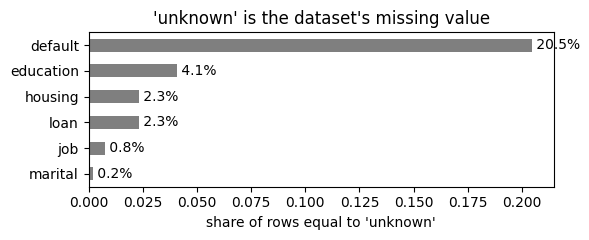

In [5]:
unk = quality["unknown_share"].dropna()
unk = unk[unk > 0].sort_values()
ax = unk.plot.barh(figsize=(6, 2.5), color="tab:gray")
ax.set_xlabel("share of rows equal to 'unknown'")
ax.set_title("'unknown' is the dataset's missing value")
for i, v in enumerate(unk):
    ax.text(v, i, f" {v:.1%}", va="center")
plt.tight_layout()

In [6]:
# Is 'unknown' informative? Subscription rate for 'unknown' vs known values.
rows = []
for c in unk.index:
    is_unk = df[c] == "unknown"
    rows.append({"column": c, "n_unknown": is_unk.sum(),
                 "rate_unknown": df.loc[is_unk, "target"].mean(),
                 "rate_known": df.loc[~is_unk, "target"].mean()})
pd.DataFrame(rows).set_index("column")

,n_unknown,rate_unknown,rate_known
column,,,
marital,18,0.056,0.113
job,76,0.066,0.113
loan,231,0.091,0.113
housing,231,0.091,0.113
education,406,0.140,0.112
default,2046,0.046,0.130


In [7]:
# housing and loan: are their 'unknown' rows the same rows?
pd.crosstab(df["housing"], df["loan"])

loan,no,unknown,yes
housing,,,
no,3919,0,600
unknown,0,231,0
yes,4377,0,873


### `pdays = 999`, `previous` and `poutcome`

`pdays = 999` means *never contacted before*. It is a code, not a number of days.

In [8]:
never = df["pdays"] == 999
print(f"pdays == 999: {never.mean():.1%} of rows")
print(f"pdays values when contacted before: {sorted(df.loc[~never, 'pdays'].unique())}")
pd.crosstab([df["pdays"] == 999], df["poutcome"], margins=True)

pdays == 999: 96.6% of rows
pdays values when contacted before: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(18), np.int64(19)]


poutcome,failure,nonexistent,success,All
pdays,,,,
False,25,0,317,342
True,976,8682,0,9658
All,1001,8682,317,10000


In [9]:
pd.crosstab([df["pdays"] == 999, df["poutcome"]], df["previous"])

previous              0    1   2   3  4  5
pdays poutcome                            
False failure         0    0  13   9  3  0
      success         0  198  78  30  7  4
True  failure         0  876  83  13  3  1
      nonexistent  8682    0   0   0  0  0

In [10]:
df.groupby(np.where(never, "never contacted (999)", "contacted before"))["target"].agg(["size", "mean"]).rename(columns={"mean": "rate"})

,size,rate
contacted before,342,0.652
never contacted (999),9658,0.094


## 4. Numeric features

In [11]:
desc = df[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["skew"] = df[num_cols].skew()
desc

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew
contact_order,10000.0,20456.797,11855.619,1.000,377.940,10174.500,20458.000,30627.750,40734.020,41178.000,0.008
age,10000.0,40.030,10.460,17.000,23.000,32.000,38.000,47.000,71.000,98.000,0.862
duration,10000.0,260.329,263.176,3.000,11.000,102.000,180.000,321.000,1313.040,3785.000,3.180
campaign,10000.0,2.582,2.802,1.000,1.000,1.000,2.000,3.000,14.000,41.000,4.709
pdays,10000.0,965.039,180.484,0.000,3.000,999.000,999.000,999.000,999.000,999.000,-5.127
previous,10000.0,0.166,0.479,0.000,0.000,0.000,0.000,0.000,2.000,5.000,3.762
emp.var.rate,10000.0,0.088,1.568,-3.400,-3.400,-1.800,1.100,1.400,1.400,1.400,-0.739
cons.price.idx,10000.0,93.578,0.579,92.201,92.201,93.075,93.749,93.994,94.465,94.767,-0.230
cons.conf.idx,10000.0,-40.495,4.621,-50.800,-50.000,-42.700,-41.800,-36.400,-26.900,-26.900,0.303
euribor3m,10000.0,3.636,1.726,0.634,0.659,1.354,4.857,4.961,4.968,5.045,-0.728


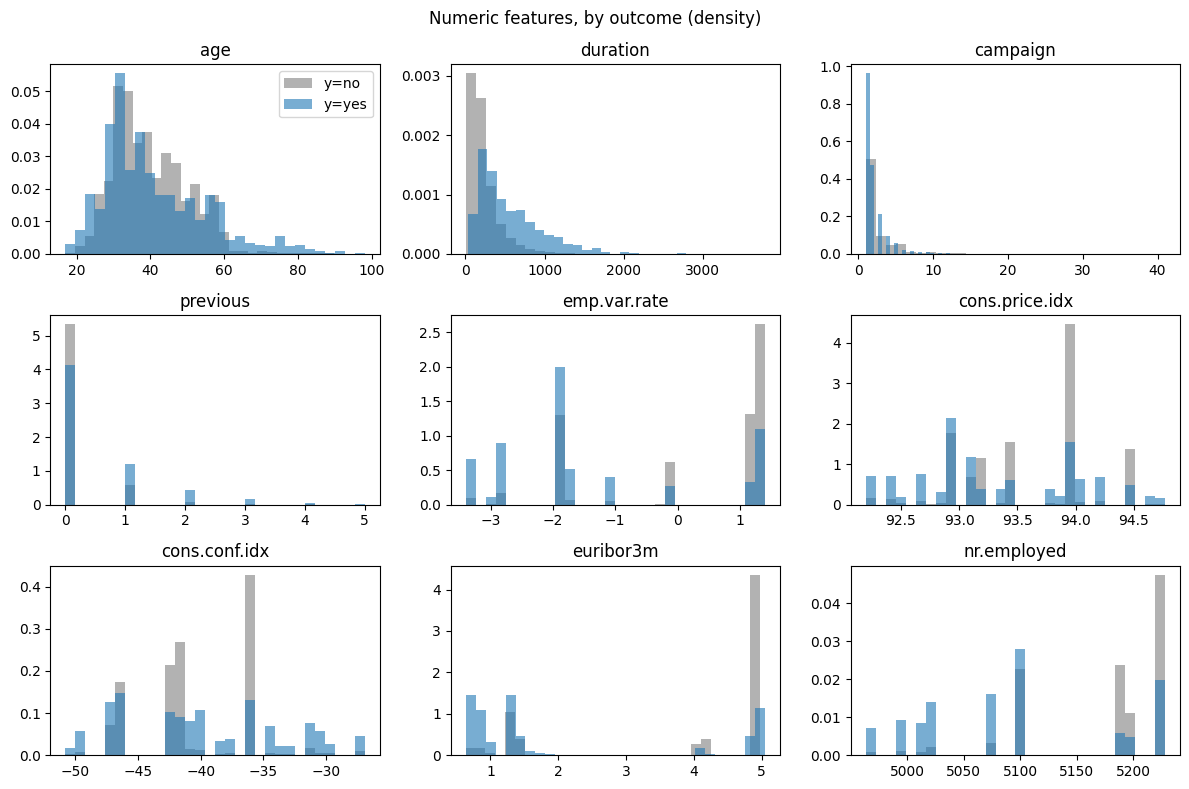

In [12]:
plot_cols = ["age", "duration", "campaign", "previous", *ECON]
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for ax, c in zip(axes.flat, plot_cols):
    for lab, color in [("no", "tab:gray"), ("yes", "tab:blue")]:
        ax.hist(df.loc[df["y"] == lab, c], bins=30, alpha=.6, density=True, color=color, label=f"y={lab}")
    ax.set_title(c)
axes.flat[0].legend()
fig.suptitle("Numeric features, by outcome (density)")
plt.tight_layout()

## 5. Categorical features

In [13]:
for c in cat_cols:
    t = df.groupby(c)["target"].agg(n="size", rate="mean")
    t["share"] = t["n"] / len(df)
    t["lift"] = t["rate"] / BASE_RATE
    t["above_break_even"] = t["rate"] > BREAK_EVEN
    print(f"\n=== {c}  ({df[c].nunique()} levels)")
    print(t.sort_values("rate", ascending=False).to_string(float_format=lambda x: f"{x:.3f}"))


=== job  (12 levels)
                  n  rate  share  lift  above_break_even
job                                                     
student         205 0.332  0.021 2.943              True
retired         413 0.254  0.041 2.256              True
unemployed      251 0.139  0.025 1.237             False
admin.         2546 0.133  0.255 1.181             False
management      697 0.113  0.070 1.006             False
technician     1615 0.112  0.162 0.994             False
self-employed   379 0.098  0.038 0.866             False
housemaid       247 0.097  0.025 0.862             False
services        952 0.082  0.095 0.727             False
entrepreneur    379 0.082  0.038 0.726             False
unknown          76 0.066  0.008 0.584             False
blue-collar    2240 0.065  0.224 0.574             False

=== marital  (4 levels)
             n  rate  share  lift  above_break_even
marital                                            
single    2775 0.136  0.278 1.205             False

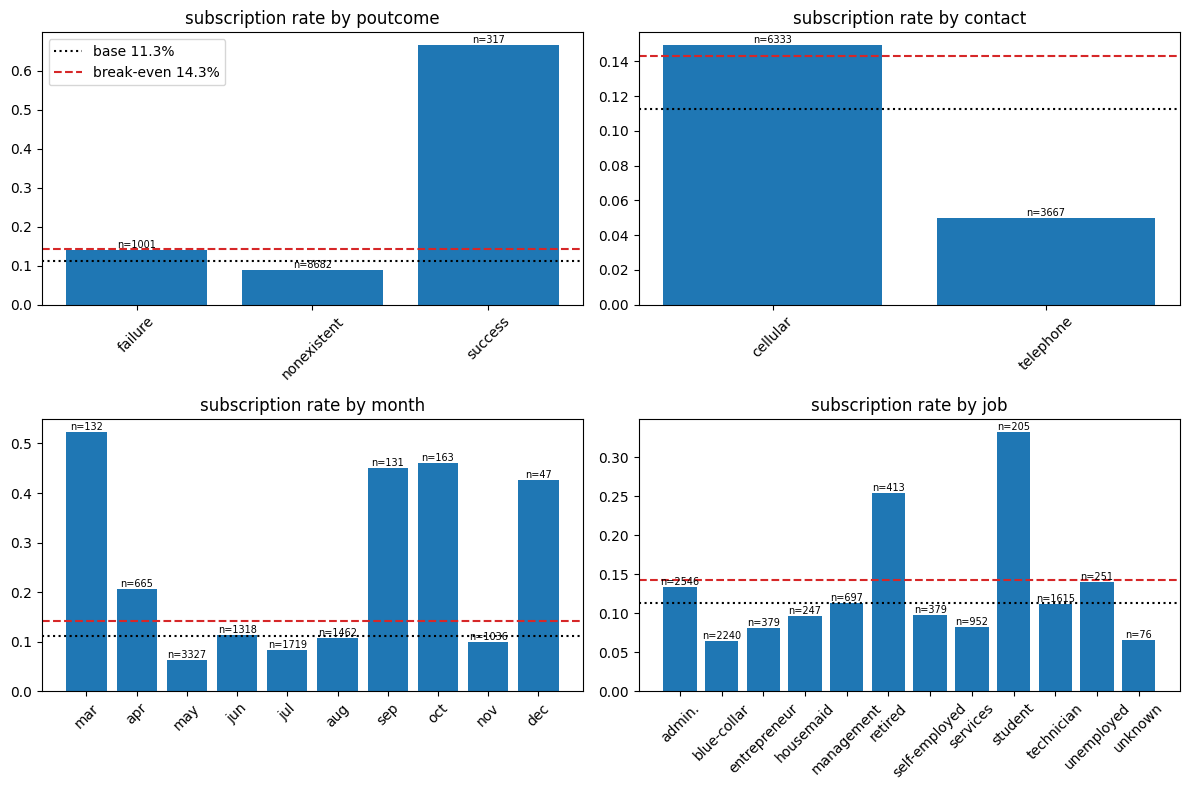

In [14]:
def rate_bar(ax, col, order=None):
    t = df.groupby(col)["target"].agg(["mean", "size"])
    if order is not None:
        t = t.reindex([o for o in order if o in t.index])
    ax.bar(t.index.astype(str), t["mean"], color="tab:blue")
    ax.axhline(BASE_RATE, color="k", ls=":", label=f"base {BASE_RATE:.1%}")
    ax.axhline(BREAK_EVEN, color="tab:red", ls="--", label=f"break-even {BREAK_EVEN:.1%}")
    for x, (r, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(x, r, f"n={n}", ha="center", va="bottom", fontsize=7)
    ax.set_title(f"subscription rate by {col}")
    ax.tick_params(axis="x", rotation=45)

months = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
rate_bar(axes[0, 0], "poutcome")
rate_bar(axes[0, 1], "contact")
rate_bar(axes[1, 0], "month", months)
rate_bar(axes[1, 1], "job")
axes[0, 0].legend()
plt.tight_layout()

## 6. Over time: `contact_order` deciles

Rows are in date order (May 2008 → Nov 2010). Does the world change across the file?

In [15]:
df["decile"] = pd.qcut(df["contact_order"], 10, labels=False) + 1
by_dec = df.groupby("decile").agg(
    first_order=("contact_order", "min"), last_order=("contact_order", "max"),
    rate=("target", "mean"), cellular=("contact", lambda s: (s == "cellular").mean()),
    contacted_before=("pdays", lambda s: (s != 999).mean()),
    top_month=("month", lambda s: s.mode()[0]),
    **{c: (c, "mean") for c in ECON})
by_dec

,first_order,last_order,rate,cellular,contacted_before,top_month,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
decile,,,,,,,,,,,
1,1,4085,0.028,0.000,0.000,may,1.100,93.994,-36.400,4.857,5191.000
2,4094,8147,0.034,0.000,0.000,may,1.123,94.031,-36.821,4.859,5193.894
3,8151,12131,0.042,0.000,0.000,jun,1.400,94.465,-41.800,4.938,5228.100
4,12132,16382,0.053,0.853,0.000,jul,1.400,93.920,-42.696,4.961,5228.100
5,16383,20452,0.063,0.918,0.000,jul,1.400,93.736,-40.159,4.965,5228.100
6,20464,24603,0.053,0.935,0.002,aug,1.159,93.415,-37.023,4.856,5222.900
7,24604,28607,0.097,0.899,0.009,nov,-0.498,93.153,-43.410,3.489,5173.075
8,28609,32694,0.116,0.948,0.025,may,-1.800,92.976,-46.610,1.361,5099.100
9,32698,36950,0.168,0.918,0.046,may,-1.997,92.905,-45.219,1.268,5095.001


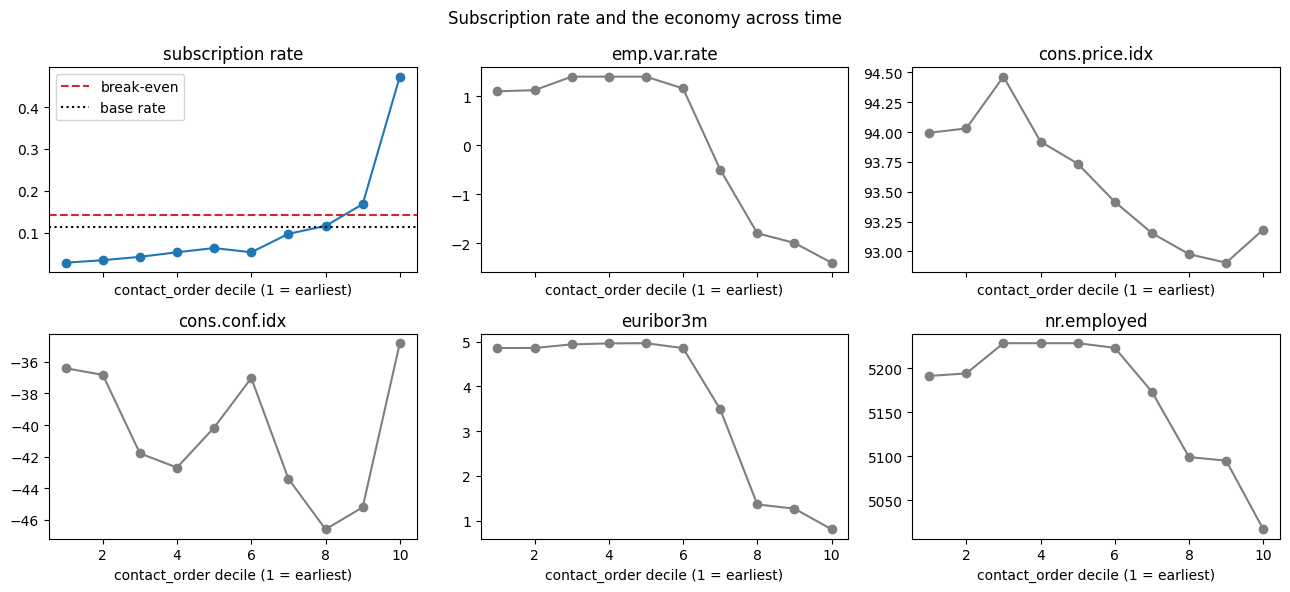

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
axes = axes.flat
axes[0].plot(by_dec.index, by_dec["rate"], "o-", color="tab:blue")
axes[0].axhline(BREAK_EVEN, color="tab:red", ls="--", label="break-even")
axes[0].axhline(BASE_RATE, color="k", ls=":", label="base rate")
axes[0].set_title("subscription rate")
axes[0].legend()
for ax, c in zip(axes[1:], ECON):
    ax.plot(by_dec.index, by_dec[c], "o-", color="tab:gray")
    ax.set_title(c)
for ax in axes:
    ax.set_xlabel("contact_order decile (1 = earliest)")
fig.suptitle("Subscription rate and the economy across time")
plt.tight_layout()

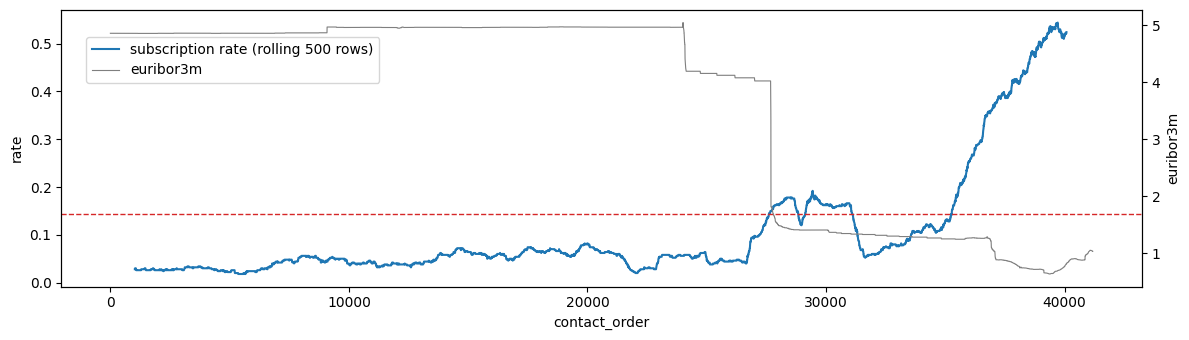

In [17]:
# Same view row by row: a rolling rate and euribor3m
roll = df["target"].rolling(500, center=True).mean()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(df["contact_order"], roll, color="tab:blue", label="subscription rate (rolling 500 rows)")
ax.axhline(BREAK_EVEN, color="tab:red", ls="--", lw=1)
ax.set_ylabel("rate")
ax2 = ax.twinx()
ax2.plot(df["contact_order"], df["euribor3m"], color="tab:gray", lw=.8, label="euribor3m")
ax2.set_ylabel("euribor3m")
ax.set_xlabel("contact_order")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.9))
plt.tight_layout()

## 7. Feature–target signal

In [18]:
# Numeric: correlation with the target, and rate by quintile.
# pdays is shown as is; 999 dominates it, so its correlation is mostly 'contacted before or not'.
corr = df[num_cols].corrwith(df["target"]).drop("contact_order").sort_values(key=abs, ascending=False)
corr.to_frame("corr_with_target")

,corr_with_target
duration,0.411
nr.employed,-0.371
euribor3m,-0.326
pdays,-0.321
emp.var.rate,-0.319
previous,0.231
cons.price.idx,-0.155
campaign,-0.070
cons.conf.idx,0.058
age,0.036


In [19]:
for c in ["age", "duration", "campaign", "euribor3m", "nr.employed"]:
    q = pd.qcut(df[c], 5, duplicates="drop")
    print(f"\n{c}")
    print(df.groupby(q, observed=True)["target"].agg(n="size", rate="mean").to_string(float_format=lambda x: f"{x:.3f}"))


age
                   n  rate
age                       
(16.999, 31.0]  2241 0.137
(31.0, 36.0]    2207 0.103
(36.0, 41.0]    1652 0.093
(41.0, 49.0]    1961 0.076
(49.0, 98.0]    1939 0.149

duration
                    n  rate
duration                   
(2.999, 88.0]    2010 0.005
(88.0, 147.0]    2009 0.031
(147.0, 223.0]   1991 0.071
(223.0, 368.0]   1994 0.131
(368.0, 3785.0]  1996 0.327

campaign
                 n  rate
campaign                
(0.999, 2.0]  6852 0.126
(2.0, 3.0]    1257 0.103
(3.0, 41.0]   1891 0.071

euribor3m
                   n  rate
euribor3m                 
(0.633, 1.299]  2035 0.316
(1.299, 4.191]  2096 0.102
(4.191, 4.864]  2089 0.033
(4.864, 4.962]  2057 0.052
(4.962, 5.045]  1723 0.055

nr.employed
                       n  rate
nr.employed                   
(4963.599, 5099.1]  3234 0.255
(5099.1, 5191.0]    1927 0.030
(5191.0, 5195.8]     922 0.052
(5195.8, 5228.1]    3917 0.050


In [20]:
# Categorical: largest lift range per column (max rate - min rate over levels with >= 30 rows)
spread = {}
for c in cat_cols:
    t = df.groupby(c)["target"].agg(["mean", "size"])
    t = t[t["size"] >= 30]
    spread[c] = {"min_rate": t["mean"].min(), "max_rate": t["mean"].max(),
                 "spread": t["mean"].max() - t["mean"].min(), "levels": len(t)}
pd.DataFrame(spread).T.sort_values("spread", ascending=False)

,min_rate,max_rate,spread,levels
poutcome,0.089,0.666,0.576,3.0
month,0.064,0.523,0.459,10.0
job,0.065,0.332,0.267,12.0
contact,0.050,0.149,0.100,2.0
default,0.046,0.130,0.083,2.0
education,0.081,0.140,0.060,7.0
day_of_week,0.086,0.130,0.044,5.0
marital,0.104,0.136,0.032,3.0
housing,0.091,0.118,0.027,3.0
loan,0.091,0.115,0.024,3.0


## 8. Redundancy between features

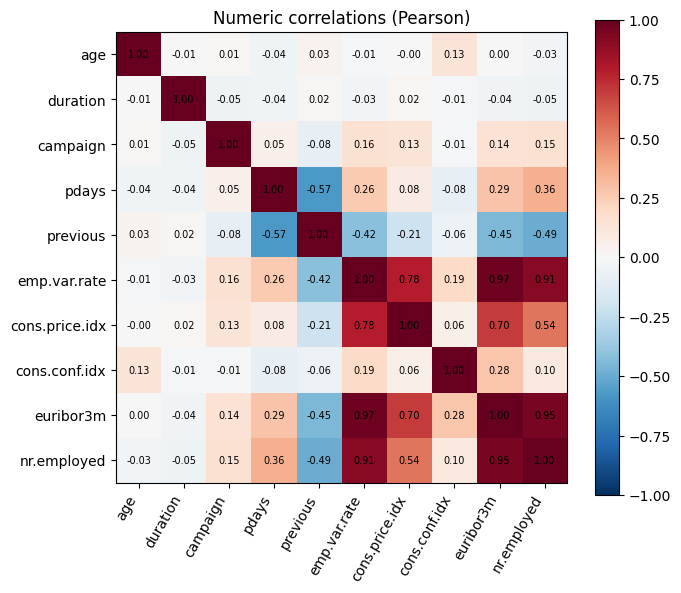

In [21]:
c = df[num_cols].drop(columns="contact_order").corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(c)), c.columns, rotation=60, ha="right")
ax.set_yticks(range(len(c)), c.columns)
for i in range(len(c)):
    for j in range(len(c)):
        ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im)
ax.set_title("Numeric correlations (Pearson)")
plt.tight_layout()

In [22]:
# Pairs with |corr| > 0.8
pairs = c.where(np.triu(np.ones(c.shape, bool), 1)).stack()
pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False).to_frame("corr")

,,corr
emp.var.rate,euribor3m,0.972
euribor3m,nr.employed,0.946
emp.var.rate,nr.employed,0.909


## 9. `duration`: known before the call?

In [23]:
print((ROOT / "data" / "bank-additional-names.txt").read_text().split("11 - duration:")[1].split("# other")[0].strip())
print()
print("rows with duration == 0:", (df["duration"] == 0).sum(), "| subscribed:", df.loc[df["duration"] == 0, "target"].sum())
print(df.groupby(pd.qcut(df["duration"], 5), observed=True)["target"].mean().to_string())

last contact duration, in seconds (numeric). Important note:  this attribute highly affects the output target (e.g., if duration=0 then y="no"). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.

rows with duration == 0: 0 | subscribed: 0
duration
(2.999, 88.0]      0.005
(88.0, 147.0]      0.031
(147.0, 223.0]     0.071
(223.0, 368.0]     0.131
(368.0, 3785.0]    0.327


## 10. Findings

**Shape and quality.** 10,000 rows × 22 columns (21 + `y`). No NaNs, no duplicate rows, no export columns. Rows are in date order; `contact_order` is unique (an identifier and a clock).

**Target.** 1,127 subscribers = **11.3%**, below the 14.3% break-even. Calling everyone loses about **€2,100 per 1,000 clients**. The model has to find pockets well above 14.3%.

**`unknown` is the missing value.** It shows up in `default` (20.5%), `education` (4.1%), `housing` and `loan` (2.3%, the **same 231 rows**), `job` (0.8%) and `marital` (0.2%). It carries information: `default = unknown` subscribes at 4.6% against 13.0% for `no`. Keep it as its own category; don't impute it. `default` has no `yes` at all, so it is really a known-vs-unknown flag.

**`pdays = 999`** means "never contacted before" (96.6% of rows). It is a code, not a number of days, so a model must not read 999 as "very long ago". Clients contacted before subscribe at **65%**, the rest at 9.4%. `pdays`, `previous` and `poutcome` describe the same history, with one quirk: 976 rows have `poutcome = failure` and `previous ≥ 1` but `pdays = 999`. `pdays` alone does not tell you about previous contact.

**Strongest signals (all known before the call):**
- `poutcome = success`: 66.6% (317 rows). That is the "simple rule" reference: about 32 calls per 1,000 clients × (0.666 × 70 − 10) ≈ **+€1,160 per 1,000**.
- `month`: mar/sep/oct/dec reach 43–52% but are rare (≈5% of rows); `may`, the busiest month, is 6.4%.
- `contact`: cellular 14.9% vs telephone 5.0%.
- `job`: student 33%, retired 25%, blue-collar 6.5%. `age` is U-shaped (≤31 and ≥50 are high), so a linear term will not capture it.
- Economy: low `euribor3m` / `nr.employed` → about 25–32% rate in the bottom quintile vs 3–5% elsewhere.
- `campaign`: more calls → lower rate (12.6% → 7.1%).
- Weak: `day_of_week`, `marital`, `housing`, `loan`, `education` (spreads of 2–6 points).

**Redundancy.** `emp.var.rate`, `euribor3m` and `nr.employed` are 0.91–0.97 correlated, effectively one "economic period" signal. This matters for the logistic regression (unstable coefficients), much less for trees.

**Time drift.** This is the biggest risk. Across `contact_order` deciles the rate climbs from **2.8% → 47%**. Over the same span euribor falls from 4.9 to 0.8, the channel switches from telephone to cellular (decile 4), and the share of previously contacted clients grows from 0 to 26%. Early and late contacts come from different worlds. A **stratified random split** (the course's choice) mixes the periods, so the test set looks like train and its profit is probably **optimistic** for "the next campaign". A chronological split would be harsher. Note this in `design.md` / the report as a limitation.

**`duration`** has the strongest correlation (0.41: 0.5% → 33% across quintiles), but per `bank-additional-names.txt` it is only known **after** the call ends, when `y` is already known.

### Evidence for the feature boundary (your decision, goes in `framing.md`)
| Column | Question to answer |
|---|---|
| `duration` | Known before deciding to call? (see §9) |
| `contact_order` | Identifier/clock: does it exist for a future client? |
| `campaign` | Counts contacts *in this campaign, including this one*. Known at the moment of the first call decision? |
| `month`, `day_of_week`, `contact` | Describe the *last* contact. Does the bank choose them before calling? Is that in scope? |
| economic columns | Known at campaign time? Keep all 3 correlated ones, or one? |
| `pdays` | Use as is, or turn into a "contacted before" flag? |

### Pre-ML expectations
- The ranking signal is real but concentrated: `poutcome = success`, rare months, cellular, students/retired, and the low-euribor period.
- After removing post-call columns, expect a modest ROC-AUC (≈0.75–0.80 range is typical for this dataset). Profit will come from a small, high-rate top slice of the list, not from calling many.
- Main risks: time drift (optimistic random-split test), the small number of positives in the test set (~225, so profit is noisy per 1,000), and the rare high-rate months, which may not repeat.
